# UKFによるパラメータ推定と外乱の同時推定


## 概要

次の運動方程式を対象とする。

$$
m \ddot{x} + d \dot{x} = u + f_e
$$

- $m$ : 質量(未知パラメータ)
- $d$ : 粘性係数(未知パラメータ)
- $u$ : 既知の制御入力
- $f_e$ : 未知の外乱力

このNoteではUKFを用いて、位置と速度の観測から、$m,d,f_e$を推定することを目標とする。

### 1. 拡張状態方程式

状態$X$を次のように未知の値とともに定義する。

$$
X = \begin{bmatrix} x \\ v \\ m \\ d \\ f_e \end{bmatrix}
$$

ここで、$m,d$は一定値、$f_e$はゆっくり変化すると仮定する。拡張状態方程式は以下となる。

$$
\dot{X} = \begin{bmatrix}
v \\[5pt]
\dfrac{u - dv + f_e}{m} \\[8pt]
0 \\[5pt]
0 \\[5pt]
0 \\[5pt]
\end{bmatrix}
$$

前進オイラー法を用いて離散拡張状態方程式は以下となる。

$$
X_{k+1} = F(X_k, u_k) + w_k \quad \rightarrow \quad 
\begin{bmatrix} x_{k+1} \\ v_{k+1} \\ m_{k+1} \\ d_{k+1} \\ f_{e,k+1} \end{bmatrix} =
\begin{bmatrix}
x_k + \Delta t v_k \\[5pt]
v_k + \Delta t \dfrac{u_k - d_k v_k + f_{e,k}}{m_k} \\[8pt]
m_k \\
d_k \\
f_{e,k}
\end{bmatrix} + w_k
$$

$w_k$は$\mathcal{N}(0, Q)$の正規分布に従う。$Q$はパラメータ、外乱の変動の許容率を含んだ以下の共分散行列である。

$$
Q = \text{diag}(q_x, q_v, q_m, q_d, q_f)
$$

### 2. 観測方程式

位置と速度の両方を観測するため、観測方程式は以下である。

$$
z_{k} = h(X_k) +r_k \quad \rightarrow \quad \begin{bmatrix}z_{x,k} \\ z_{v,k} \end{bmatrix}
= \begin{bmatrix}
1 & 0 & 0 & 0 & 0 \\
0 & 1 & 0 & 0 & 0 \\
\end{bmatrix}
\begin{bmatrix} x_{k} \\ v_{k} \\ m_{k} \\ d_{k} \\ f_{e,k} \end{bmatrix} + r_k
$$

$r_k$は$\mathcal{N}(0, R)$の正規分布に従う。$R$は状態$x,v$を計測時に生じるノイズを表す以下の共分散行列である。

$$
R = \text{diag}(\sigma_{x}^2, \sigma_{v}^2)
$$


### 3. UKFによる1ループ

[理論はこのNote](./UKF-theory.ipynb)に記述し、[テストケースはこのNote](./Estimate_State_using_UKF.ipynb)にまとめている。

パラメータと外乱推定でも状態が増えてること以外はUKFの計算方法に変化はない。

以下の計算する内容の次元を示す。

- 状態数 $nx=5$
- 観測数 $nz=2$
- 推定状態 $\hat{x}_{k|k} \in \mathcal{R}^{5 \times 1}$
- 誤差共分散行列 $P_{k|k} \in \mathcal{R}^{5 \times 5}$
- シグマポイント $\chi_{k|k} \in \mathcal{R}^{5 \times 1}$
- シグマポイント $\psi_{k+1|k} \in \mathcal{R}^{5 \times 1}$
- シグマポイント $Z_{k+1} \in \mathcal{R}^{2 \times 1}$
- 観測値の予測値 $\hat{z}_{k+1|k} \in \mathcal{R}^{2 \times 1}$
- 観測値の予測誤差共分散 $S_{k+1} \in \mathcal{R}^{2 \times 2}$
- 交差共分散 $P_{xz} \in \mathcal{R}^{5 \times 2}$
- Kalman Gain $K \in \mathcal{R}^{5 \times 2}$

### 4. Python Code

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from dataclasses import dataclass, field


In [2]:
@dataclass
class Parameters:

    dt:float  = 1e-3 # Simulation Step

    m:float = 10 # 慣性 [kg]
    d:float = 0.1 # 粘性 [N s/m]

    # 状態数
    nx : int = 5

    # 観測数
    nz : int = 2

    # 誤差共分散行列の初期値
    P_init : np.ndarray = field(
        default_factory=lambda: np.diag([1e2, 1e2,1e-1, 1e-1, 1e-1]), compare=False
    )

    # 実機のプロセスノイズの分散Q
    Q_real: np.ndarray = field(
        default_factory=lambda: np.diag([1e-3, 1e-3]), compare=False
    )

    # プロセスノイズの分散Q
    Q: np.ndarray = field(
        default_factory=lambda: np.diag([1e-5, 1e-5, 1e-4, 1e-4, 1e-4]), compare=False
    )

    # 観測ノイズの分散R
    R: np.ndarray = field(
        default_factory=lambda: np.diag([1e-3, 1e-3]), compare=False
    )

    alpha:float  = 1.0
    beta:float = 2.0
    kappa:float = 0.0

def real_system(X_n:np.ndarray, u_n:float, fe_n: float, params:Parameters):
    x_n, v_n = X_n
    x_next = x_n + params.dt * v_n
    v_next = v_n + params.dt/params.m*(u_n - params.d * v_n + fe_n)
    return np.array([x_next,v_next])

def fake_real_system(X_n:np.ndarray, u_n:float, params:Parameters):
    x_n, v_n, m_n, d_n, fe_n = X_n
    x_next = x_n + params.dt * v_n
    v_next = v_n + params.dt/m_n*(u_n - d_n * v_n + fe_n)
    m_next = m_n
    d_next = d_n
    fe_next = fe_n
    return np.array([x_next,v_next, m_next, d_next, fe_next])

def mesure_value(X_n:np.ndarray):
    return X_n

def fake_mesurement_value(X_n:np.ndarray):
    x_n, v_n, _ , _ , _ = X_n
    return np.array([x_n, v_n])

def process_noize(params:Parameters):
    return np.random.multivariate_normal(mean=np.zeros(2), cov=params.Q_real)

def mesurement_noiz(params:Parameters):
    return np.random.multivariate_normal(mean=np.zeros(2), cov=params.R)

def generate_sigma_points(x_mean:np.ndarray, P:np.ndarray, params:Parameters):
    n = params.nx
    lam = params.alpha**2*(n + params.kappa) - n
    U = np.linalg.cholesky((n + lam) * P)

    # シグマポイントの計算
    sigmas = np.zeros((2*n + 1, n))
    sigmas[0] = x_mean
    for i in range(n):
        sigmas[i+1] = x_mean + U[:,i]
        sigmas[n+i+1] = x_mean - U[:,i]

    return sigmas

def genrate_weights(params:Parameters):
    n = params.nx
    lam = params.alpha**2*(n + params.kappa) - n
    # 重み計算
    weights_mean = np.zeros(2*n + 1)
    weights_cov = np.zeros(2*n + 1)

    weights_mean[0] = lam / (n+lam)
    weights_cov[0] = weights_mean[0] + (1 - params.alpha**2 + params.beta)

    for i in range(1, 2*n+1):
        weights_mean[i] = 1.0 / (2*(n + lam))
        weights_cov[i] = weights_mean[i]

    return weights_mean, weights_cov

In [3]:
def calculate_UKF_one_loop(hat_x:np.ndarray, P:np.ndarray, u:float, z:np.ndarray, params:Parameters):

    # シグマポイントを計算
    sigmas = generate_sigma_points(hat_x, P, params)
    # 重みの計算
    w_m , w_c = genrate_weights(params)

    # シグマポイントを状態方程式に通過させる
    chis = np.array([fake_real_system(s, u, params) for s in sigmas])

    # 事前推定値の状態を計算
    x_pred = np.sum(w_m[:, None] * chis, axis=0)

    # 事前推定値の分散を計算
    P_pred = params.Q.copy()
    for i in range(len(w_m)):
        diff = chis[i] - x_pred
        P_pred += w_c[i] * np.outer(diff, diff)
    # 対称行列化
    P_pred = 0.5*(P_pred + P_pred.T)

    # シグマポイントを計算
    psi = generate_sigma_points(x_pred, P_pred, params)

    # シグマポイントを観測方程式に通過させる
    Z = np.array([fake_mesurement_value(s) for s in psi])

    # 予測観測値を求める
    z_pred = np.sum(w_m[:, None]* Z, axis=0)

    # 観測値の予測誤差共分散を求める
    S_pred = params.R.copy()
    for i in range(len(w_m)):
        diff = Z[i] - z_pred
        S_pred += w_c[i] * np.outer(diff, diff)

    # 交差共分散を求める
    Pxz = np.zeros((params.nx, params.nz))
    for i in range(len(w_m)):
        diff_x = psi[i] - x_pred
        diff_z = Z[i] - z_pred
        Pxz += w_c[i] * np.outer(diff_x, diff_z)

    # カルマンゲインの計算
    K = np.linalg.solve(S_pred, Pxz.T).T

    # innovation
    tilde_z = z - z_pred

    # 事後推定 状態
    x_est = x_pred + K @ tilde_z

    # 事後推定 共分散行列
    P_est = P_pred - K @ S_pred @ K.T
    # 対称行列化
    P_est = 0.5*(P_est + P_est.T)

    return x_est, P_est



In [81]:
def simulation(X_init: np.ndarray,X_est_init:np.ndarray, u_array:np.ndarray, fe_array:np.ndarray, params:Parameters, feedback=False):

    X_history = []
    X_est_history = []
    P_history = []
    time_array = []
    u_history = []

    X_history.append(X_init)
    X_est_history.append(X_est_init)
    P_history.append(params.P_init.copy())
    time_array.append(0)
    P_est = params.P_init
    n = len(u_array)
    last_e = 0

    for i in range(n):
        X_for_sim = X_history[i].copy()
        if feedback:
            posi, vel = X_for_sim
            p_gain = 10
            d_gain = 3
            e = u_array[i] - posi
            u_input = e * p_gain - vel * d_gain
            last_e = e
        else:
            u_input = u_array[i]

        w_real = process_noize(params)

        # システムの状態
        X_real = real_system(X_for_sim, u_input, fe_array[i], params) + w_real

        # システムの観測値
        z = mesure_value(X_real) + mesurement_noiz(params)

        # UFKによる状態推定
        X_est, P_est = calculate_UKF_one_loop(X_est_history[i], 
                                              P_est, 
                                              u_input, 
                                              z, 
                                              params,
                                              )

        X_est_history.append(X_est)
        X_history.append(X_real)
        P_history.append(P_est.copy())
        u_history.append(u_input)

        time_array.append(params.dt * (i+1))

    return np.asarray(time_array), np.asarray(X_history), np.asarray(X_est_history), np.asarray(P_history), np.asarray(u_history)


In [72]:
def create_fig(t_array, x_array, x_est_array, u_array, fe_array, params:Parameters, title=""):

    fig, ax = plt.subplots(6,1, figsize=(10,8))

    ax[0].set_ylabel("Position[m]")
    ax[0].plot(t_array, x_array[:,0], label="real")
    ax[0].plot(t_array, x_est_array[:,0], label="est")

    ax[1].set_ylabel("Speed[m/s]")
    ax[1].plot(t_array, x_array[:,1], label="real")
    ax[1].plot(t_array, x_est_array[:,1], label="est")

    ax[2].set_ylabel("mass [kg]")
    ax[2].axhline(params.m , color="tab:blue", linestyle="--", label="real")
    ax[2].plot(t_array, x_est_array[:,2], color="tab:orange", label="est")

    ax[3].set_ylabel("viscosity [N s/m]")
    ax[3].axhline(params.d , color="tab:blue", linestyle="--", label="real")
    ax[3].plot(t_array, x_est_array[:,3], color="tab:orange", label="est")

    ax[4].set_ylabel("disturbance [N]")
    ax[4].plot(t_array[:len(fe_array)], fe_array , label="real")
    ax[4].plot(t_array, x_est_array[:,4], label="est")

    ax[5].set_ylabel("Input u [N]")
    ax[5].plot(t_array[:len(u_array)], u_array, label="control input")

    for i in range(6):
        ax[i].grid()
        ax[i].grid(which='minor', lw=0.1, color='grey')
        ax[i].minorticks_on()

        ax[i].legend(loc="upper right")

    plt.suptitle(title)
    plt.tight_layout()
    plt.show()

### パラメータ推定

$f_e = 0$として、パラメータ推定を実施。

$u$に対して、以下の信号を入力

- ramp
- sine
- white noize
- periodic square 

また比較として、位置をsineで制御する方法も行う

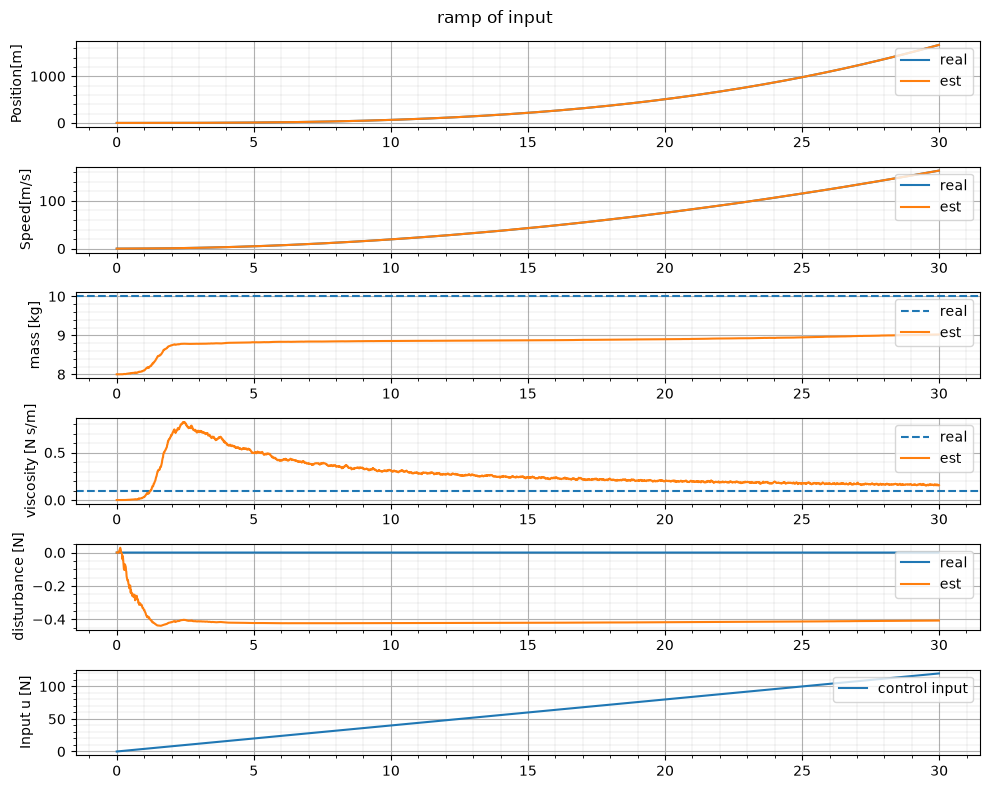

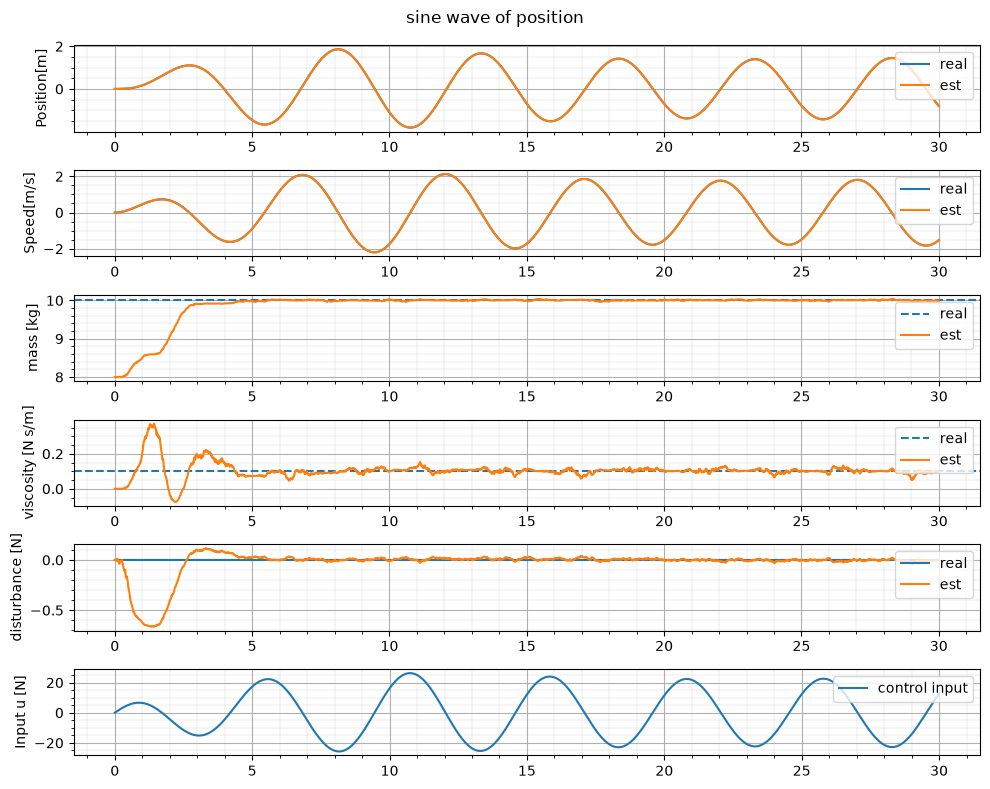

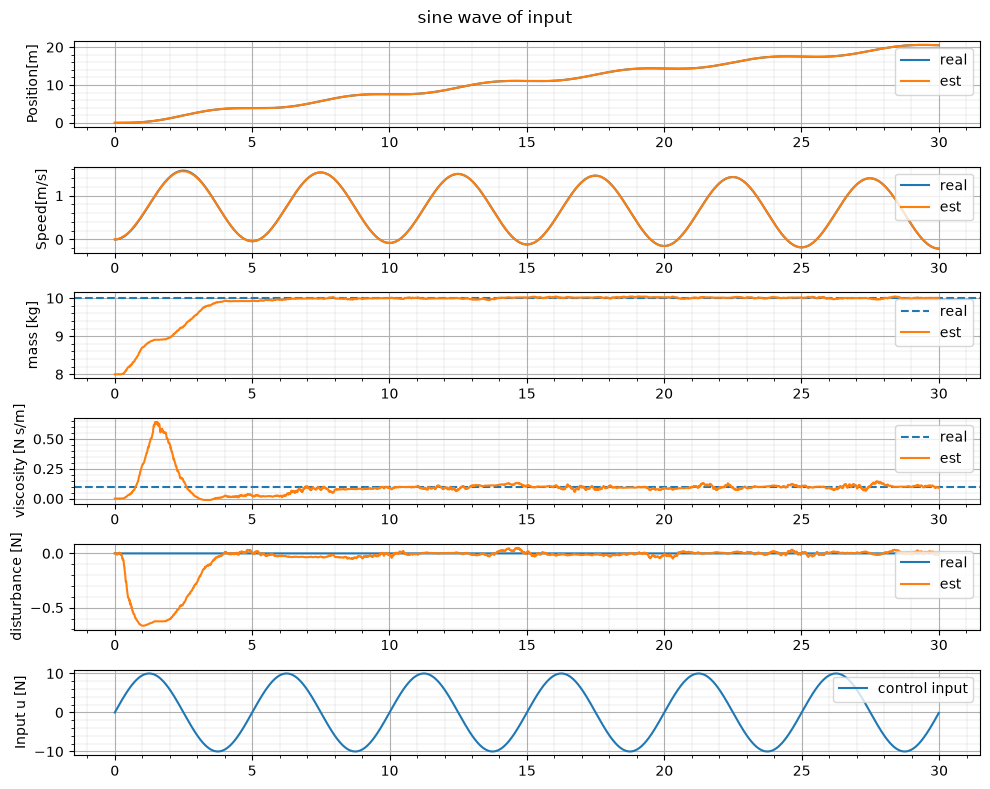

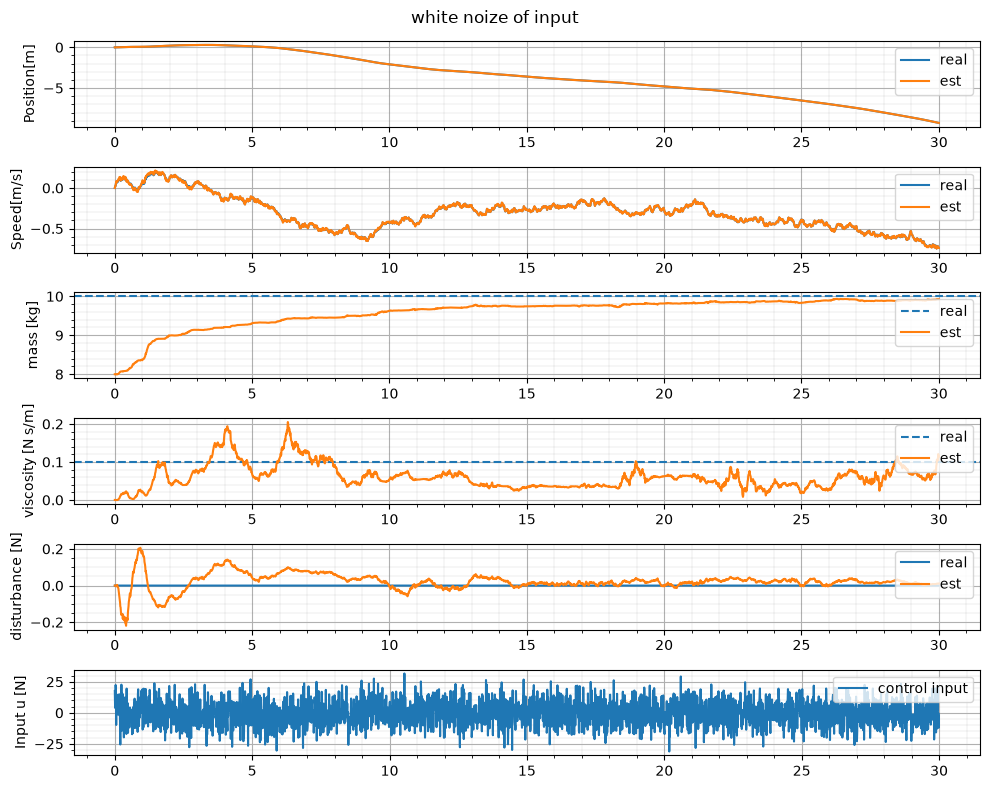

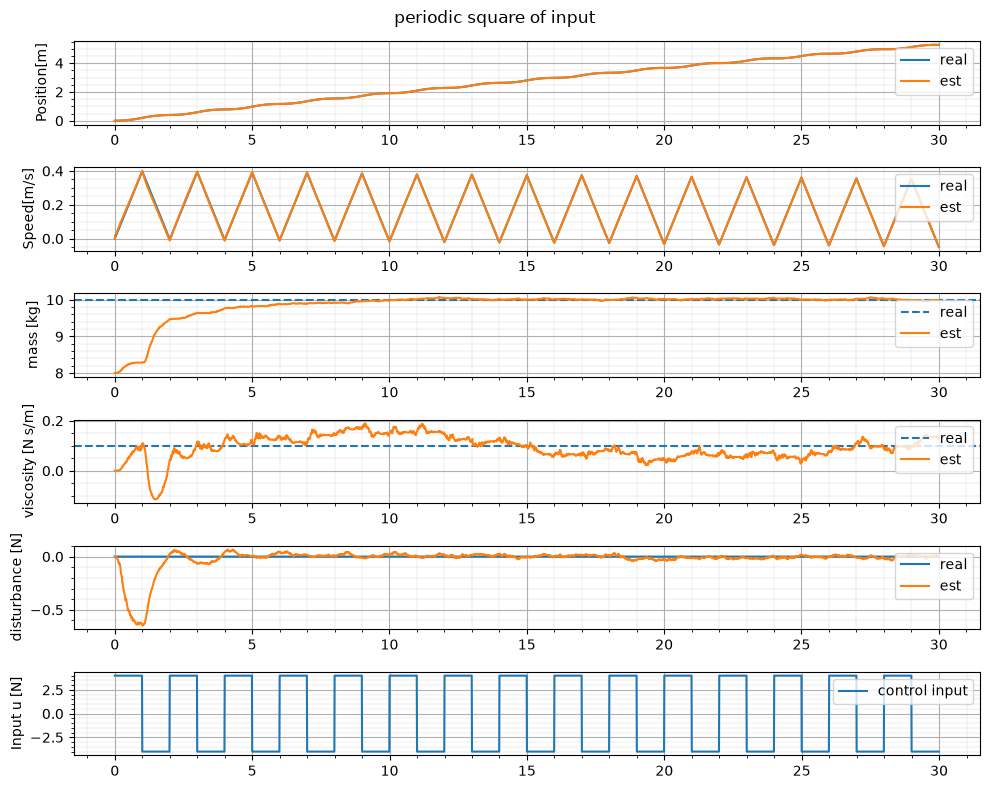

In [90]:
np.random.seed(0)

dt = 1e-2 # [s]
duration = 30 #[s]
sampling_point = int(duration/dt)
time_window = np.arange(sampling_point) * dt

params = Parameters(
    dt = dt,
    m = 10,
    d = 0.1,
    Q_real = np.diag([1e-8, 1e-8]), 
    Q = np.diag([1e-8, 1e-8, 1e-5, 1e-5, 1e-5]), # プロセスノイズ
    R = np.diag([1e-4, 1e-4]), # 観測ノイズ
    P_init = np.diag([1e2, 1e2, 1e-2, 1e-2, 1e-2]) # 誤差共分散行列の初期値
)

# 制御入力

# ramp
ramp_array = time_window * 4

white_noize = np.random.normal(loc=0, scale=10, size=len(time_window))


# 正弦波
amplitude = 1.0  # 振幅 [N]
frequency = 0.2  # 周波数 [Hz]（周期5秒）
omega = 2 * np.pi * frequency
sine_array = amplitude * np.sin(2 * np.pi * frequency * time_window)


#
s_wave = (
    -amplitude * omega**2 * np.cos(omega * time_window)
    -amplitude * omega* np.sin(omega * time_window)
) 

# 矩形波
period = 2.0
high_time = period/2

periodic_square_wave = np.where(
    time_window % period < high_time,
    4.0,
    -4.0
)

u_input = ramp_array

fe_array = np.zeros_like(u_input)


X_init = np.array([0.0, 0.0])
X_est_init = np.array([0.0, 0.0, 8.0, 0.0, 0.0])


t_array, x_array, x_est_array, p_array, u_array = simulation(X_init = X_init,
                                                    X_est_init = X_est_init,
                                                    u_array = u_input,
                                                    fe_array = fe_array,
                                                    params = params)

create_fig(t_array, x_array, x_est_array, u_array, fe_array, params, title="ramp of input")

u_input = sine_array

t_array, x_array, x_est_array, p_array, u_array = simulation(X_init = X_init,
                                                    X_est_init = X_est_init,
                                                    u_array = u_input,
                                                    fe_array = fe_array,
                                                    params = params,
                                                    feedback=True)

create_fig(t_array, x_array, x_est_array, u_array, fe_array, params, title="sine wave of position")


t_array, x_array, x_est_array, p_array, u_array = simulation(X_init = X_init,
                                                    X_est_init = X_est_init,
                                                    u_array = u_input * 10,
                                                    fe_array = fe_array,
                                                    params = params,
                                                    feedback=False)

create_fig(t_array, x_array, x_est_array, u_array, fe_array, params, title="sine wave of input")

u_input = white_noize

t_array, x_array, x_est_array, p_array, u_array = simulation(X_init = X_init,
                                                    X_est_init = X_est_init,
                                                    u_array = u_input,
                                                    fe_array = fe_array,
                                                    params = params)

create_fig(t_array, x_array, x_est_array, u_array, fe_array, params, title="white noize of input")

u_input = periodic_square_wave

t_array, x_array, x_est_array, p_array, u_array = simulation(X_init = X_init,
                                                    X_est_init = X_est_init,
                                                    u_array = u_input,
                                                    fe_array = fe_array,
                                                    params = params)

create_fig(t_array, x_array, x_est_array, u_array, fe_array, params, title="periodic square of input")



結果は以下となった。

- ramp : 収束しない
- white noize : 緩やかな収束
- periodic square : 収束
- sine wave of position : 素早い収束
- sine wave of input : 素早い収束

以上より、周期的な運動であれば、今回のモデルでは収束できるといえる。

これは、質量$m$が加速度、粘性$d$が速度に対応し、これは90度ずれで生じる。周期的な運動では

- 加速度が極大時は、速度がゼロ
- 速度が極大時は、加速度がゼロ

となるため、質量と粘性の分離が行いやすくなるためと考えられる。

今回の運動方程式は変形すると以下となる。

$$
u_k = m a_k + d v_k - f_e
$$

未知パラメータを$\theta$

$$
\theta = \begin{bmatrix} m \\ d \\ f_e \end{bmatrix}
$$

回帰ベクトルを$\phi_k$とすると、

$$
\phi_k = \begin{bmatrix} a_k \\ v_k \\ -1 \end{bmatrix}
$$

運動方程式は以下となる。

$$
u_k = \phi_k^T \theta
$$

これを変形すると、

$$
\phi_k u_k = \phi_k \phi_k^T \theta \rightarrow \theta = \left(\phi_k \phi_k^T \right)^{-1} \phi_k u_k
$$

よって、$G_k = \phi_k \phi_k^T$が正則であれば、$\theta$を求めることが出来る。しかし$G_k$は

$$
G_k = \phi_k \phi_k^T= \begin{bmatrix} a_k \\ v_k \\ -1 \end{bmatrix} \begin{bmatrix} a_k & v_k & -1 \end{bmatrix}
= \begin{bmatrix} 
a_k^2 & a_k v_k & -a_k \\
v_k a_k & v_k^2 & -v_k \\
-a_k & - v_k & 1 
\end{bmatrix} = \begin{bmatrix} a_k \phi_k & v_k \phi_k & -\phi_k \end{bmatrix}
$$

のようになるため、列変形を行い

$$
G_k \sim \begin{bmatrix}  a_k \phi_k - a_k \phi_k & v_k \phi_k - v_k \phi_k & -\phi_k \end{bmatrix} = \begin{bmatrix} 0 & 0 & -\phi_k \end{bmatrix}
$$

のように行列となり、$\theta$を求めることが出来ない。

そこで各時刻で以下のように足し合わせを行うことで、

$$
\sum_{k=0}^n \phi_k u_k = \left(\sum_{k=0}^n \phi_k \phi_k^T \right) \theta
$$

$G$を以下のように定義する。

$$
G = \sum_{k=0}^n \phi_k \phi_k^T 
$$

この$G$は$\phi_k$が線形独立であれば、例えば$n=2$として、3つの回帰ベクトルを並べる

$$
\Phi = \begin{bmatrix} \phi_0^T \\ \phi_1^T \\ \phi_2^T \end{bmatrix} =
\begin{bmatrix}
a_0 & v_0 & -1 \\
a_1 & v_1 & -1 \\
a_2 & v_2 & -1
\end{bmatrix}
$$

このとき

$$
G_{0:2} = \sum_{k=0}^2 \phi_k \phi_k^T = \Phi^T \Phi
$$

であり、$\phi_0, \phi_1, \phi_2$ が線形独立であれば、rank($\Phi$)=3 であり、rank($\Phi^T\Phi$) = rank($\Phi$) = 3 となるため、$G_{0:2}$は正則となり、$\theta$を求めることが出来る。これが時間による累積でパラメータを推定できる理由である。

$n=4$である場合も

$$
\Phi = \begin{bmatrix} \phi_0^T \\ \phi_1^T \\ \phi_2^T \\ \phi_3^T \\ \phi_4^T \end{bmatrix} =
\begin{bmatrix}
a_0 & v_0 & -1 \\
a_1 & v_1 & -1 \\
a_2 & v_2 & -1 \\
a_3 & v_3 & -1 \\
a_4 & v_4 & -1 \\
\end{bmatrix}
$$

$$
G_{0:4} = \Phi^T \Phi \in \mathbf{R}^{3 \times 3}
$$

となり、5個の回帰ベクトルのうち３個が線形独立であれば、 rank($G_{0:4}$) = 3 となり、パラメータを推定できる。

#### 持続的励振 について

これは未知パラメータを識別するために必要な情報が、運動の中に継続して含まれていることを意味している。

上記では、$G_{0:n}$が正則であれば、観測期間中のパラメータ$\theta$は一意に識別可能ということを示した。

以下では、まず、$m,d,f_e$が観測期間中に一定であると仮定して、パラメータの識別可能性を考える。

持続的励振の条件は

ある正の整数$N$と正の定数$\alpha$が存在して、全ての時刻$k$について

$$
\sum_{i=k}^{k+N-1}\phi_i \phi_i^T \succeq \alpha I_3
$$

が成立することを考える。上式のそれぞれは以下と意味する。

- $N$ : 情報を蓄積する時間窓の長さ
- $\alpha > 0 $ : 情報行列の最小固有値に対する下限
- $\succeq$ : 左辺と右辺の差が半正定値であること

例えば速度$v(t), a(t)$の関係が以下であるとき、

$$
v(t) = A \sin(\omega t) \rightarrow a(t) =  A \omega \cos(\omega t)
$$

回帰ベクトルは以下となる。

$$
\phi(t) = \begin{bmatrix}
A \omega \cos(\omega t) \\
A \sin(\omega t) \\
-1
\end{bmatrix}
$$

1周期$T=2\pi/\omega$ にわたって情報行列を計算すると、

$$
G_T = \int_0^T \phi(t) \phi(t)^T dt
$$

$$
\phi(t)\phi(t)^T = 
\begin{bmatrix}
A^2 \omega^2 \cos^2(\omega t) & A^2 \omega \cos(\omega t) \sin(\omega t) & - A \omega \cos(\omega t) \\
A^2 \omega \cos(\omega t) \sin(\omega t) & A^2 \sin^2(\omega t) & - A \sin(\omega t) \\
- A \omega \cos(\omega t) & - A \sin(\omega t) & 1
\end{bmatrix}
$$

これらを積分すると、

$$
G_T = \begin{bmatrix}
\dfrac{A^2 \omega^2 T}{2} & 0 & 0 \\
0 & \dfrac{A^2 T}{2} & 0 \\
0 & 0 & T
\end{bmatrix}
$$

となり、$A \neq 0, \omega \neq 0$ でれば、$G_T$は正則となる。したがって、理想的な正弦波運動は持続的励振の条件を満たすことが出来る。

これが、正弦波入力がパラメータの推定がうまくできた理由である。

### 外乱が時系列に変わる場合

正弦波、white noize 入力を使い、外乱が変化する場合のパラメータと外乱の推定を行う。

外乱の変化は以下とする。

- 正弦波
- ステップ

### 正弦波外乱の検討

In [117]:
def calc_G(x_array, params:Parameters):
    a = np.diff(x_array[:,1])/params.dt
    v = x_array[:-1,1]

    Phi = np.column_stack([
        a,
        v,
        -np.ones_like(v)
    ])

    # 情報行列
    G = Phi.T @ Phi * params.dt
    print("G = \n", G)
    print("eigen values =", np.linalg.eigvals(G))

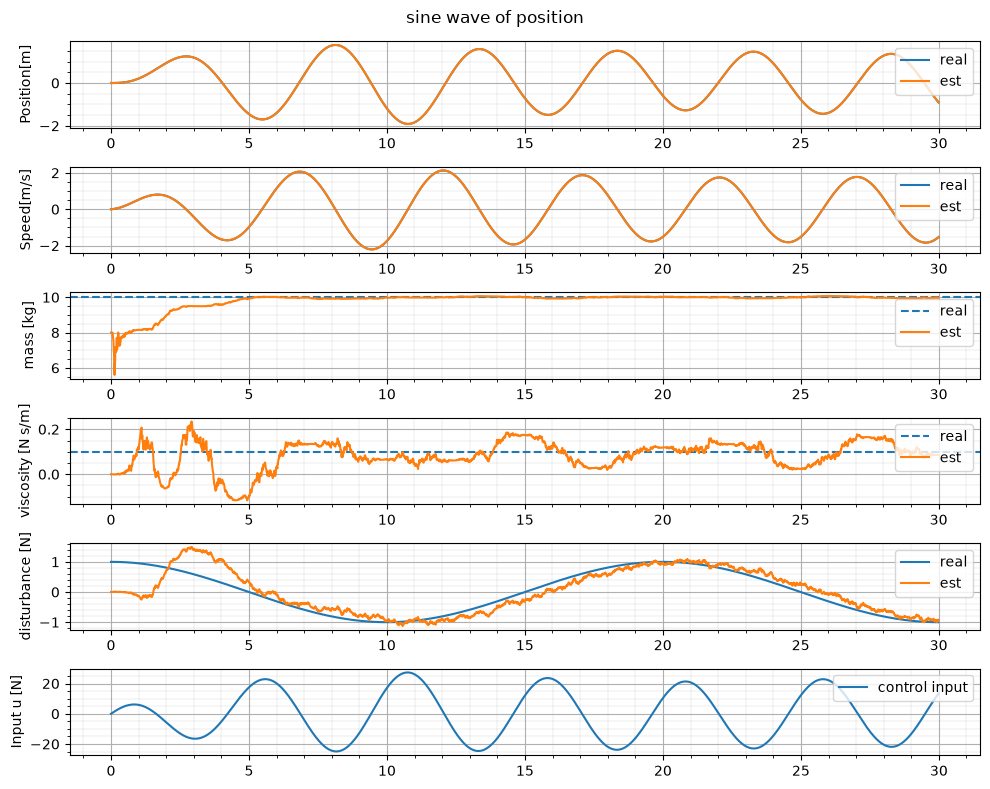

G = 
 [[75.10574219  0.79479085  1.52991474]
 [ 0.79479085 50.8051419   0.90688674]
 [ 1.52991474  0.90688674 30.        ]]
eigen values = [75.18551428+0.j 29.91112327+0.j 50.81424654+0.j]


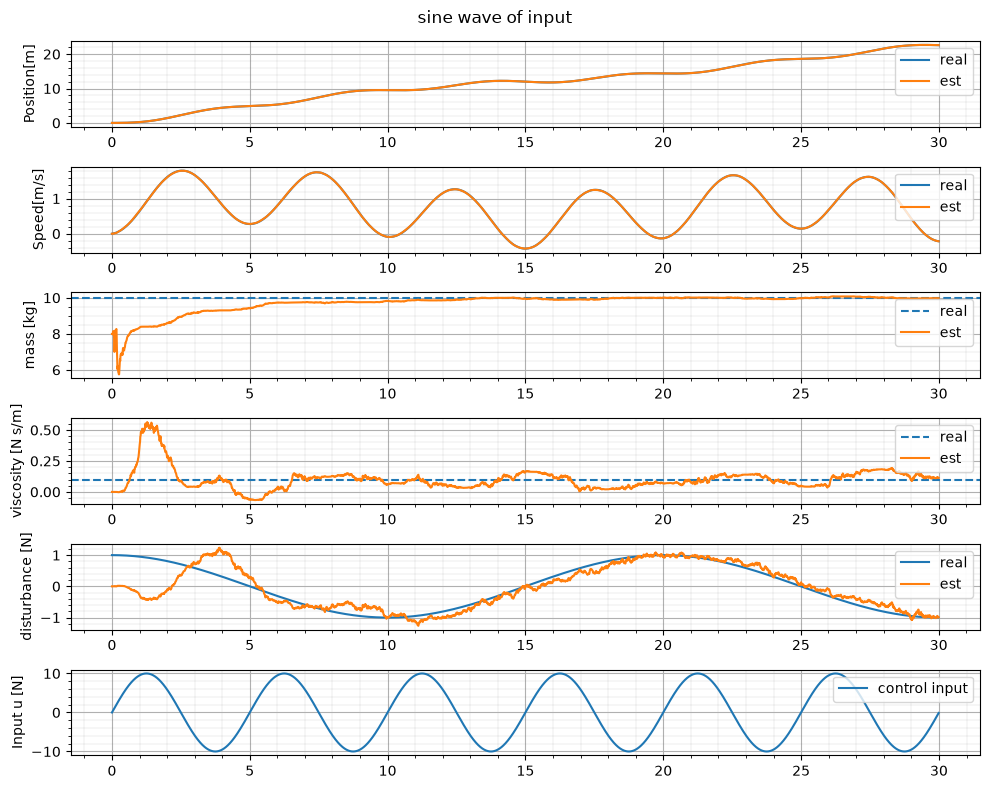

G = 
 [[ 15.48802167  -0.05411975   0.21596462]
 [ -0.05411975  28.22309311 -22.60981424]
 [  0.21596462 -22.60981424  30.        ]]
eigen values = [51.7398395 +0.j 15.48835235+0.j  6.48292293+0.j]


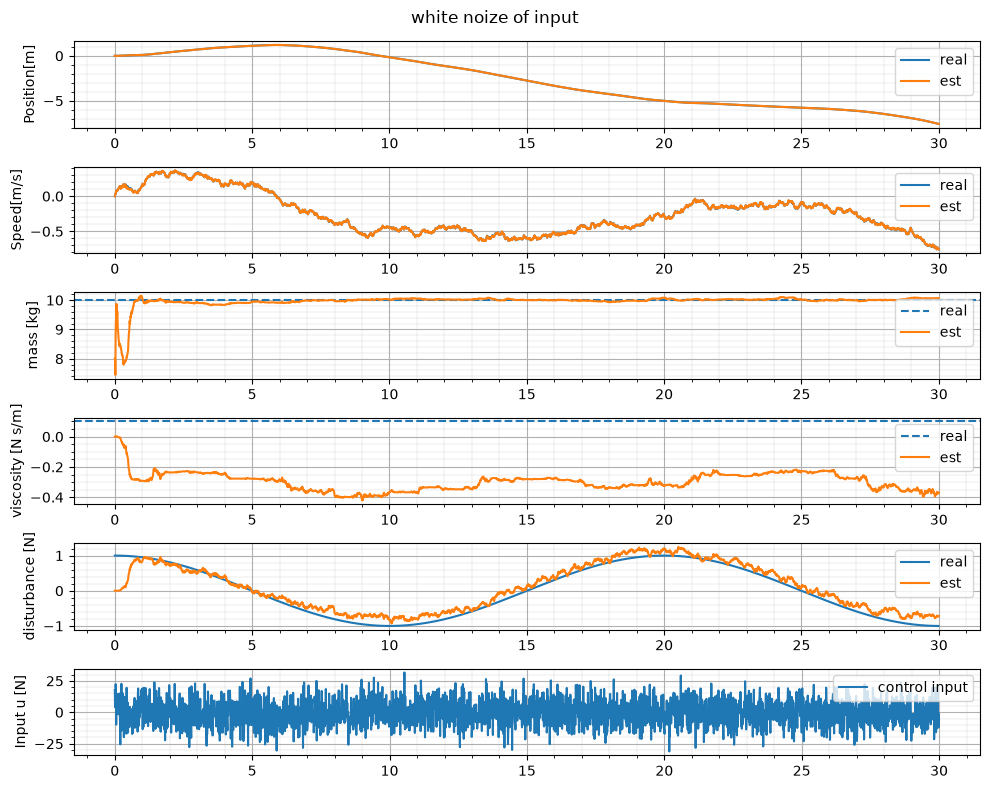

G = 
 [[28.41852205  0.14407079  0.75652284]
 [ 0.14407079  4.2417606   7.57021974]
 [ 0.75652284  7.57021974 30.        ]]
eigen values = [28.26338502+0.j 32.21536149+0.j  2.18153614+0.j]


In [118]:
np.random.seed(0)

dt = 1e-2 # [s]
duration = 30 #[s]
sampling_point = int(duration/dt)
time_window = np.arange(sampling_point) * dt

params = Parameters(
    dt = dt,
    m = 10,
    d = 0.1,
    Q_real = np.diag([1e-8, 1e-8]), 
    Q = np.diag([1e-8, 1e-8, 2e-5, 2e-5, 5e-4]), # プロセスノイズ
    R = np.diag([1e-4, 1e-4]), # 観測ノイズ
    P_init = np.diag([1e2, 1e2, 4, 5e-2, 1e-3]) # 誤差共分散行列の初期値
)

# 制御入力

# 正弦波
amplitude = 1.0  # 振幅 [N]
frequency = 0.2  # 周波数 [Hz]（周期5秒）
omega = 2 * np.pi * frequency
sine_array = amplitude * np.sin(2 * np.pi * frequency * time_window)

white_noize = np.random.normal(loc=0, scale=10, size=len(time_window))

# 外乱
amp_d = 1.0
freq_d = 0.05
omega_d = 2 * np.pi * freq_d
fe_array = amp_d * np.cos( omega_d * time_window)

# 
X_init = np.array([0.0, 0.0])
X_est_init = np.array([0.0, 0.0, 8.0, 0.0, 0.0])



u_input = sine_array

t_array, x_array, x_est_array, p_array, u_array = simulation(X_init = X_init,
                                                    X_est_init = X_est_init,
                                                    u_array = u_input,
                                                    fe_array = fe_array,
                                                    params = params,
                                                    feedback=True)

create_fig(t_array, x_array, x_est_array, u_array, fe_array, params, title="sine wave of position")

calc_G(x_array,params)

u_input = sine_array

t_array, x_array, x_est_array, p_array, u_array = simulation(X_init = X_init,
                                                    X_est_init = X_est_init,
                                                    u_array = u_input * 10,
                                                    fe_array = fe_array,
                                                    params = params,
                                                    feedback=False)

create_fig(t_array, x_array, x_est_array, u_array, fe_array, params, title="sine wave of input")

calc_G(x_array,params)

u_input = white_noize

t_array, x_array, x_est_array, p_array, u_array = simulation(X_init = X_init,
                                                    X_est_init = X_est_init,
                                                    u_array = u_input,
                                                    fe_array = fe_array,
                                                    params = params,
                                                    feedback=False)

create_fig(t_array, x_array, x_est_array, u_array, fe_array, params, title="white noize of input")

calc_G(x_array,params)




結果は

- 位置正弦波 : オーバーシュートがあまりなく$m,d,f_e$が収束している。推定パラメータ・外乱はある程度振動している。
- 入力正弦波 : オーバーシュートは多少あるが$m,d,f_e$は収束している。推定パラメータ・外乱はある程度振動している。
- white noize : $m$と$f_e$は収束しているが、$d$は収束していない。

やはり、継続的励振の運動がパラメータ・外乱推定には必要と考える。

情報行列$G$を確認すると、white noizeの場合の2,2 要素、これは$d$に関する項目、がほかのGと比べて小さくなっている。これにより、$d$の推定がうまくできていないと考える。この2,2要素はvの積分値であり、white noizeの速度応答値は0 から -0.5付近と小さいためである。
